# Landing Page A/B Test Analysis

Step by step walkthrough of the same pipeline that `python -m src.run_analysis` runs. All statistics come from `src/ab_test.py`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.ab_test import (SEED, remove_assignment_mismatches, deduplicate_users,
                         analyze_ab_test)
from src import run_analysis as ra

np.random.seed(SEED)
raw = ra.load()
raw.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


## 1. Cleaning

Control must see `old_page`, treatment must see `new_page`. Anything else is a routing or tracking error.

In [2]:
print(raw.shape, 'unique users:', raw.user_id.nunique())
pd.crosstab(raw.group, raw.landing_page)

(294478, 5) unique users: 290584


landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


In [3]:
matched, mm = remove_assignment_mismatches(raw, 'group', 'landing_page',
                                           {'control': 'old_page', 'treatment': 'new_page'})
clean, dd = deduplicate_users(matched, 'user_id', 'timestamp')
print('mismatched rows removed:', mm['mismatched_rows'], mm['mismatch_breakdown'])
print('duplicate rows removed:', dd['duplicate_rows_removed'])
print('rows left:', len(clean), '| unique users lost:', raw.user_id.nunique() - clean.user_id.nunique())
pd.DataFrame(dd['duplicate_examples'])

mismatched rows removed: 3893 [{'group': 'control', 'landing_page': 'new_page', 'rows': 1928}, {'group': 'treatment', 'landing_page': 'old_page', 'rows': 1965}]
duplicate rows removed: 1
rows left: 290584 | unique users lost: 0


,user_id,timestamp,group,landing_page,converted
0,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
1,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


## 2 to 4. Sanity checks, core result, power

In [4]:
res = analyze_ab_test(clean, 'group', 'converted', time_col='timestamp',
                      alpha=ra.ALPHA, mde_abs=ra.MDE_ABS, power=ra.POWER)
daily = res.pop('_daily')
print(json.dumps({k: res[k] for k in ['srm', 'duration', 'test', 'power', 'decision']}, indent=1, default=str))

{
 "srm": {
  "counts": {
   "control": 145274,
   "treatment": 145310
  },
  "observed_share": {
   "control": 0.4999380557773312,
   "treatment": 0.5000619442226688
  },
  "chi2": 0.004459984032155934,
  "p_value": 0.9467543681597944
 },
 "duration": {
  "start": "2017-01-02 13:42:05.378582",
  "end": "2017-01-24 13:41:54.460509",
  "days": 21.999873633414353,
  "calendar_days": 23
 },
 "test": {
  "rate_control": 0.1203863045004612,
  "rate_treatment": 0.11880806551510564,
  "ci_control": [
   0.11871294722381814,
   0.12205966177710426
  ],
  "ci_treatment": [
   0.11714442856134422,
   0.12047170246886707
  ],
  "abs_lift": -0.0015782389853555567,
  "rel_lift": -0.01310978845894809,
  "abs_ci": [
   -0.003937860245052736,
   0.0007813822743416229
  ],
  "rel_ci": [
   -0.03271020122590149,
   0.0064906243080053135
  ],
  "z": -1.3109241984234394,
  "p_value": 0.18988337448195103,
  "alpha": 0.05,
  "significant": false,
  "bootstrap_abs_ci": [
   -0.0038495381843887027,
   0.00092

Cross check the z test against statsmodels.

In [5]:
from statsmodels.stats.proportion import proportions_ztest
z, p = proportions_ztest([res['conversions_treatment'], res['conversions_control']],
                         [res['n_treatment'], res['n_control']])
print(f'statsmodels z = {z:.4f}, p = {p:.4f} | ours z = {res["test"]["z"]:.4f}, p = {res["test"]["p_value"]:.4f}')
assert np.isclose(z, res['test']['z']) and np.isclose(p, res['test']['p_value'])

statsmodels z = -1.3109, p = 0.1899 | ours z = -1.3109, p = 0.1899


## 5. Daily trend (novelty check)

In [6]:
print(json.dumps(res['trend'], indent=1))
daily.iloc[1:-1].round(4)

{
 "days_used": 21,
 "slope_per_day": -0.00013035716805213273,
 "slope_p_value": 0.5344713834628394,
 "first_half_mean_diff": 6.452586224535428e-06,
 "second_half_mean_diff": -0.003161840291187004,
 "days_treatment_ahead": 6,
 "min_daily_share": 0.49289954166353595,
 "max_daily_share": 0.5054870203587376
}


,users_control,users_treatment,rate_control,rate_treatment,treatment_share,abs_diff
date,,,,,,
2017-01-03,6590,6618,0.1138,0.1138,0.5011,-0.0000
2017-01-04,6578,6541,0.1219,0.1166,0.4986,-0.0053
2017-01-05,6427,6505,0.1232,0.1150,0.5030,-0.0082
2017-01-06,6606,6747,0.1153,0.1235,0.5053,0.0081
2017-01-07,6604,6609,0.1210,0.1162,0.5002,-0.0048
2017-01-08,6687,6700,0.1189,0.1207,0.5005,0.0019
2017-01-09,6628,6615,0.1196,0.1181,0.4995,-0.0016
2017-01-10,6654,6696,0.1129,0.1263,0.5016,0.0135
2017-01-11,6688,6673,0.1189,0.1151,0.4994,-0.0038


## 6. Segment check

The source repository has no `countries.csv`, so there is no country breakdown.

## Full pipeline: charts, results.json and README

In [7]:
res = ra.main()
ra.print_summary(res)

KEY NUMBERS
  rows in / out           294,478 / 290,584 (3,893 mismatched, 1 duplicate)
  users per group         145,274 old / 145,310 new (SRM p = 0.947)
  test length             22 days
  conversion              12.04% old vs 11.88% new
  lift                    -0.16 pts (-1.3% relative)
  95% CI (points)         [-0.39, +0.08]
  z / p                   -1.31 / 0.190
  worthwhile lift         0.5 pts, power 98.4%
  detectable at 80%       0.34 pts
  decision                keep old page


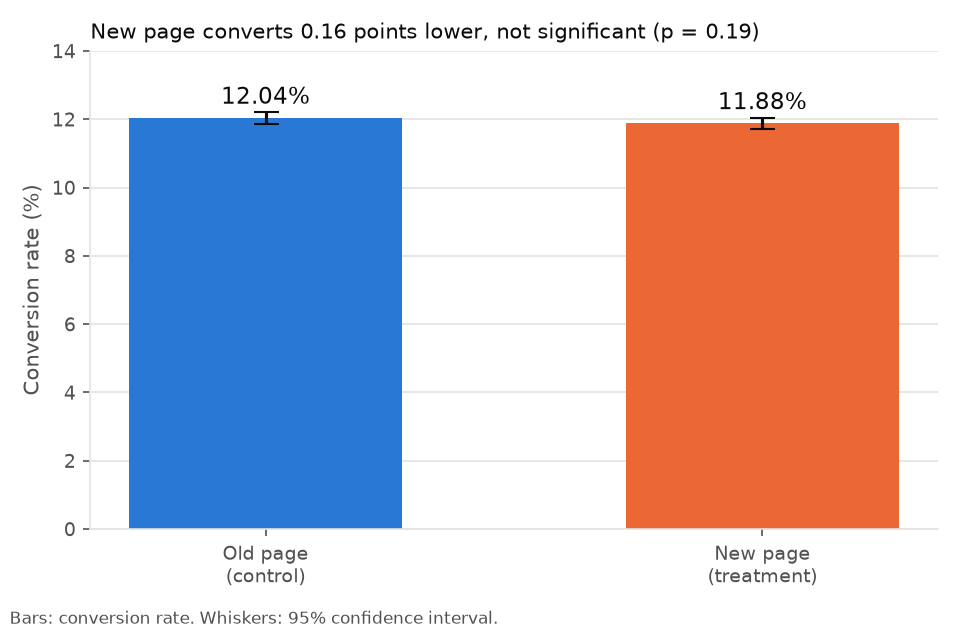

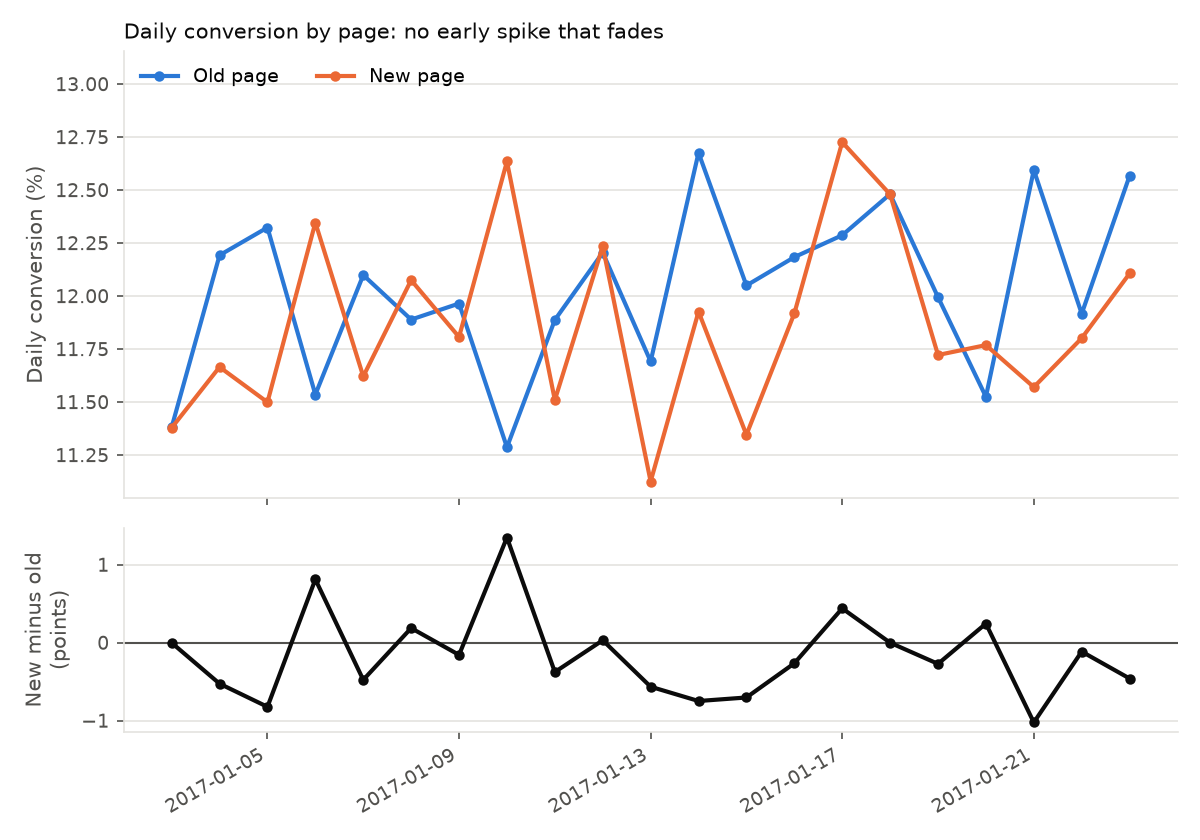

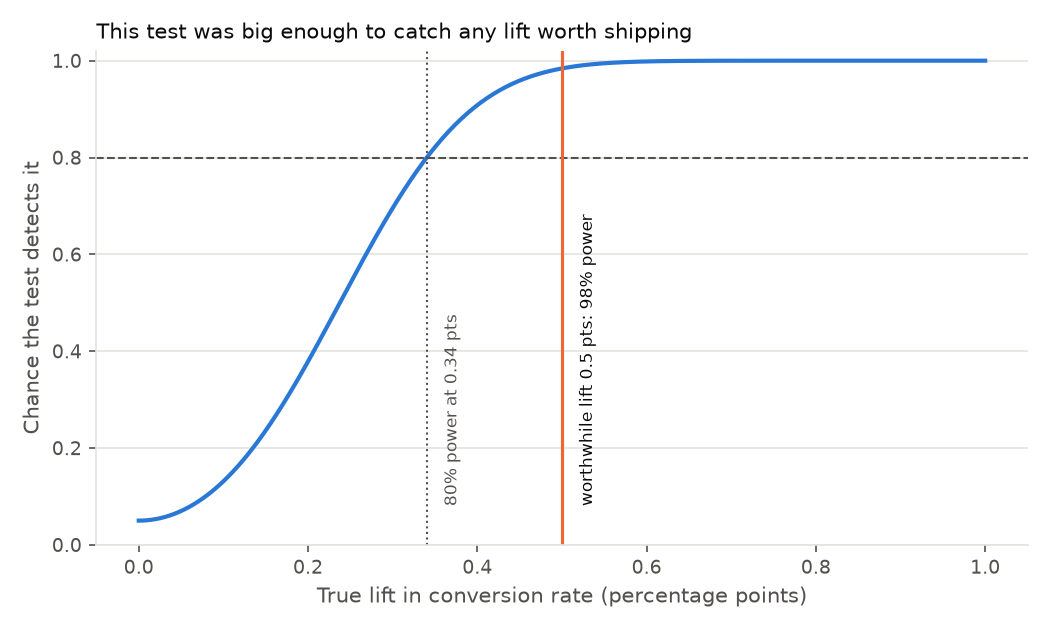

In [8]:
for f in ['conversion_by_group', 'daily_conversion_trend', 'power_curve']:
    display(Image(filename=str(ROOT / 'reports' / 'figures' / f'{f}.png')))